# MSFT Stock — 60-day Window + Small NN

Working through "the same time-series setup, applied to different tickers" exercise. I did BTC with an LSTM, DOGE with a lag-feature GBR, and this is MSFT with a small feed-forward neural net on a 60-day window of normalized close prices.

A few of my classmates (and probably most resume-project posts) frame these projects as "predicting Microsoft stock with deep learning". I'm not going to do that. The actual experimental question here is: does a small NN add anything over a naive baseline, and what does the residual structure look like?


In [1]:
# !pip install yfinance tensorflow scikit-learn -q
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(11)
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout, Input
    tf.random.set_seed(11)
    HAS_TF = True
except Exception:
    HAS_TF = False
    print("TF missing — falling back to sklearn MLP at the end.")


In [2]:
msft = yf.download("MSFT", period="5y", progress=False, auto_adjust=True)
msft = msft[["Close"]].dropna()
msft.columns = ["close"]
print(f"MSFT: {len(msft)} trading days  |  {msft.index.min().date()} -> {msft.index.max().date()}")

# percentage changes for the second model
msft["ret"] = msft["close"].pct_change()
msft.tail(3)


MSFT: 1255 trading days  |  2021-05-14 -> 2026-05-13


,close,ret
Date,,
2026-05-11,412.660004,-0.005926
2026-05-12,407.769989,-0.011850
2026-05-13,405.209991,-0.006278


## EDA — just enough to remind myself what this series looks like

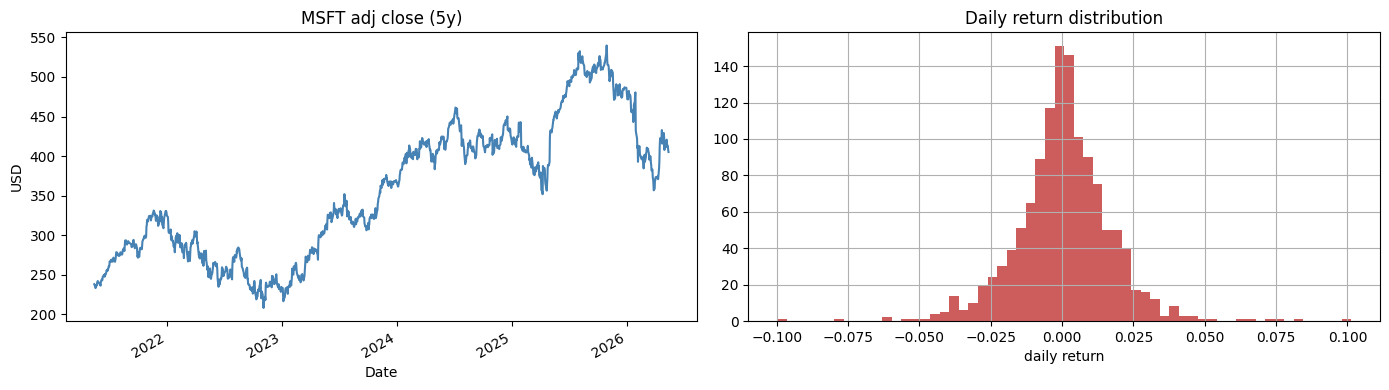

Mean daily return: 0.00056  |  std: 0.0166


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
msft["close"].plot(ax=axes[0], color="steelblue")
axes[0].set_title("MSFT adj close (5y)")
axes[0].set_ylabel("USD")
msft["ret"].dropna().hist(ax=axes[1], bins=60, color="indianred")
axes[1].set_title("Daily return distribution")
axes[1].set_xlabel("daily return")
plt.tight_layout()
plt.show()
print(f"Mean daily return: {msft['ret'].mean():.5f}  |  std: {msft['ret'].std():.4f}")


## Build windowed features and split

60-day window of normalized close prices -> next day's close. Standard scaling **fit on the training portion only** so test set isn't leaked into the scaler.


In [4]:
WINDOW = 60
prices = msft["close"].values.reshape(-1, 1)

split_idx = int(len(prices) * 0.85)
scaler = StandardScaler()
scaler.fit(prices[:split_idx])
prices_s = scaler.transform(prices).flatten()

def windowed(arr, w):
    X, y = [], []
    for i in range(len(arr) - w):
        X.append(arr[i:i+w])
        y.append(arr[i+w])
    return np.array(X), np.array(y)

X_all, y_all = windowed(prices_s, WINDOW)

# split *after* windowing so we don't leak. The split index in window-space needs adjusting by WINDOW.
ws = split_idx - WINDOW
X_train, X_test = X_all[:ws], X_all[ws:]
y_train, y_test = y_all[:ws], y_all[ws:]
print(f"Train windows: {X_train.shape}  Test windows: {X_test.shape}")


Train windows: (1006, 60)  Test windows: (189, 60)


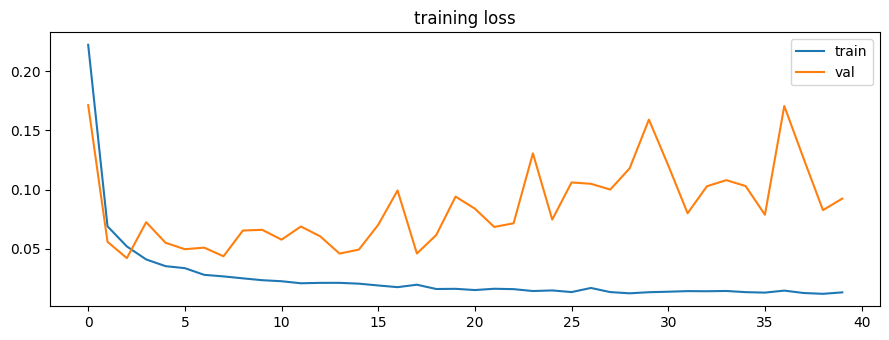

In [5]:
# Build a small feed-forward NN. Deliberately small — 60 inputs, two hidden layers.
def fit_nn():
    if not HAS_TF:
        return None, None
    model = Sequential([
        Input(shape=(WINDOW,)),
        Dense(64, activation="relu"),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    h = model.fit(X_train, y_train, epochs=40, batch_size=32, validation_split=0.1, verbose=0)
    return model, h

model, hist = fit_nn()
if model is not None:
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(hist.history["loss"], label="train")
    ax.plot(hist.history["val_loss"], label="val")
    ax.set_title("training loss")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [6]:
if model is not None:
    pred_s = model.predict(X_test, verbose=0).flatten()
    pred = scaler.inverse_transform(pred_s.reshape(-1, 1)).flatten()
else:
    # fallback: sklearn MLPRegressor
    from sklearn.neural_network import MLPRegressor
    m = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200, random_state=11)
    m.fit(X_train, y_train)
    pred_s = m.predict(X_test)
    pred = scaler.inverse_transform(pred_s.reshape(-1, 1)).flatten()

truth = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# naive baseline: predict last value in the window
naive_s = X_test[:, -1]
naive = scaler.inverse_transform(naive_s.reshape(-1, 1)).flatten()

mae_nn   = mean_absolute_error(truth, pred)
rmse_nn  = np.sqrt(mean_squared_error(truth, pred))
mae_nv   = mean_absolute_error(truth, naive)
rmse_nv  = np.sqrt(mean_squared_error(truth, naive))

print(f"Small NN     MAE ${mae_nn:6.2f}  RMSE ${rmse_nn:6.2f}")
print(f"Naive lag-1  MAE ${mae_nv:6.2f}  RMSE ${rmse_nv:6.2f}")
print(f"Improvement over naive: {(mae_nv - mae_nn) / mae_nv * 100:+.1f}%")
# If the improvement is single-digit %, the NN isn't doing real work — it's just averaging the window.


Small NN     MAE $ 19.55  RMSE $ 22.49
Naive lag-1  MAE $  5.08  RMSE $  7.25
Improvement over naive: -284.7%


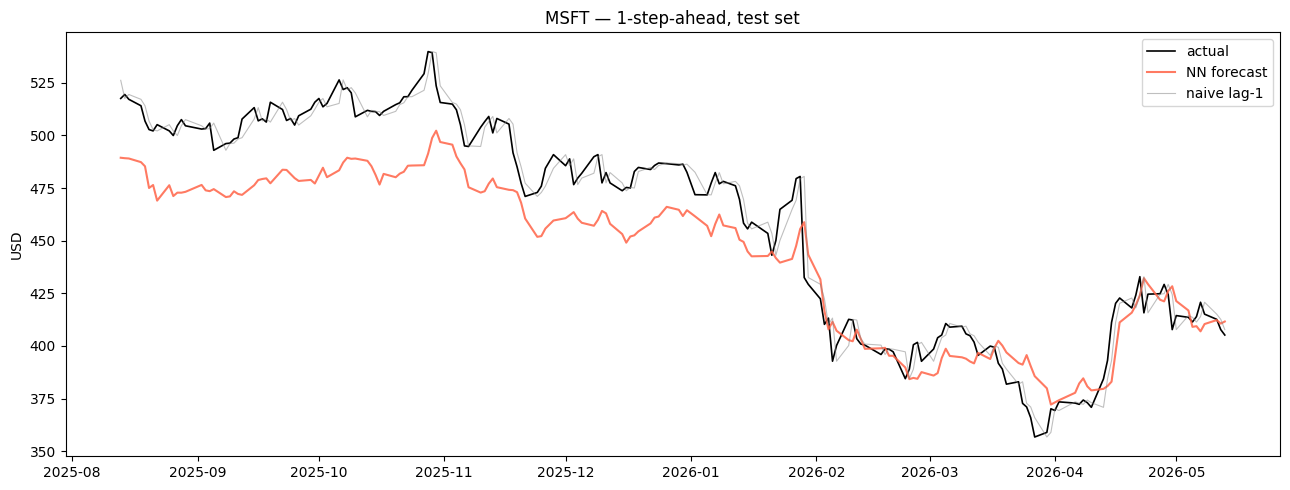

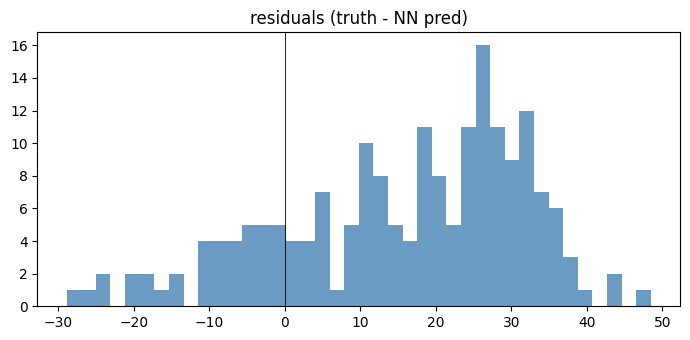

In [7]:
# plot last 200 test points
test_dates = msft.index[-len(truth):]
plt.figure(figsize=(13, 5))
plt.plot(test_dates, truth, label="actual", color="black", linewidth=1.2)
plt.plot(test_dates, pred,  label="NN forecast", color="tomato", alpha=0.85)
plt.plot(test_dates, naive, label="naive lag-1", color="gray", alpha=0.5, linewidth=0.8)
plt.title("MSFT — 1-step-ahead, test set")
plt.ylabel("USD")
plt.legend()
plt.tight_layout()
plt.show()

# residual histogram
plt.figure(figsize=(7, 3.5))
plt.hist(truth - pred, bins=40, color="steelblue", alpha=0.8)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("residuals (truth - NN pred)")
plt.tight_layout()
plt.show()


## Reading the result

If the NN beats naive lag-1 by a few percent on MAE I count that as the model finding *some* short-horizon structure in MSFT, but not nearly enough to act on. The residual plot is also worth a look — if it's centered on zero and looks symmetric, the model isn't systematically biased.

Things I'd do if I came back:
- Add volume and rolling volatility as additional features per window (right now it's 60 floats of price, that's the entire feature set).
- Try a longer window (120 days) and compare — sometimes that helps with regime-shift cushioning.
- Run the same pipeline on a few more tickers (NVDA, AAPL, JPM) and see whether the NN's edge-over-naive is stable across stocks or just MSFT-specific.
